# Müşteri Kaybı (Churn) Tahmini
## Logistic Regression ve Random Forest Karşılaştırması

Bu not defteri, yönergedeki 3.1 ila 3.8 adımlarını sırayla izler. Hücreleri yukarıdan aşağıya çalıştırın.

**Veri seti:** Telco Customer Churn, IBM'in halka açık GitHub deposundan alınmıştır (github.com/IBM/telco-customer-churn-on-icp4d). Bir telekom şirketinin 7043 müşterisi, 19 özellik ve hedef değişken `Churn`. Veri yalnızca eğitim amacıyla kullanılmıştır.

## 1. Problem Tanımı

**Girdi:** müşterinin sözleşme türü, abonelik süresi, aylık ücreti, aldığı hizmetler ve ödeme yöntemi.
**Hedef çıktı:** müşterinin hizmeti bırakıp bırakmayacağı (Evet / Hayır), yani ikili sınıflandırma.
**Gerçek dünya ihtiyacı:** Yeni müşteri kazanmak, mevcut müşteriyi elde tutmaktan genellikle daha pahalıdır. Ayrılma olasılığı yüksek müşterileri önceden bulan bir model, şirketin bu kişilere indirim veya arama gibi bir elde tutma teklifi yapmasını sağlar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, precision_recall_curve)

RANDOM_STATE = 42
R = {}  # sonuçları toplamak için

## 2. Veri Setinin Tanıtılması

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    # Bağlantı çalışmazsa aynı dosyayı Colab'a yükleyip adıyla okuyun
    df = pd.read_csv("Telco-Customer-Churn.csv")

print("Boyut (satır, sütun):", df.shape)
print("Eksik değer (isnull):", df.isnull().sum().sum())
print("Tekrarlayan müşteri kimliği:", df["customerID"].duplicated().sum())
df.head()

Boyut (satır, sütun): (7043, 21)
Eksik değer (isnull): 0
Tekrarlayan müşteri kimliği: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.dtypes)
oran = df["Churn"].value_counts()
print("\nSınıf dağılımı:")
print(oran)
print("Churn oranı: %", round((df["Churn"] == "Yes").mean() * 100, 1))
R["ham_shape"] = list(df.shape)
R["churn_sayisi"] = int((df["Churn"] == "Yes").sum())
R["kalan_sayisi"] = int((df["Churn"] == "No").sum())
R["churn_orani"] = round(float((df["Churn"] == "Yes").mean()), 4)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Sınıf dağılımı:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn oranı: % 26.5


**Veri sözlüğü (özet)**

| Sütun | Anlam |
|---|---|
| customerID | Müşteri kimliği (modelde kullanılmaz) |
| gender, SeniorCitizen, Partner, Dependents | Demografik bilgiler |
| tenure | Abonelik süresi (ay) |
| PhoneService, MultipleLines, InternetService | Telefon ve internet hizmetleri |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | Ek hizmetler |
| StreamingTV, StreamingMovies | Yayın hizmetleri |
| Contract | Sözleşme türü (aylık, 1 yıllık, 2 yıllık) |
| PaperlessBilling, PaymentMethod | Fatura ve ödeme yöntemi |
| MonthlyCharges, TotalCharges | Aylık ve toplam ücret |
| Churn | Hedef: müşteri ayrıldı mı (Yes / No) |

**Sınıf dengesizliği:** Müşterilerin yaklaşık dörtte biri ayrılmış. Hiç model kurmadan herkese "kalacak" desek bile accuracy yaklaşık %73.5 çıkar. Bu yüzden yalnızca accuracy yanıltıcıdır, recall ve F1 de izlenmelidir.

## 3. Veri Keşfi

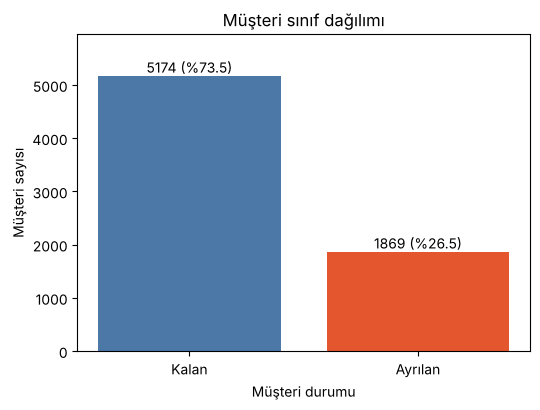

In [4]:
# Grafik 1: sınıf dağılımı
sayilar = df["Churn"].value_counts().reindex(["No", "Yes"])
plt.figure(figsize=(5.5, 4.2))
bars = plt.bar(["Kalan", "Ayrılan"], sayilar.values, color=["#4C78A8", "#E4572E"])
for b, v in zip(bars, sayilar.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 60, f"{v} (%{v / len(df) * 100:.1f})", ha="center")
plt.title("Müşteri sınıf dağılımı")
plt.xlabel("Müşteri durumu")
plt.ylabel("Müşteri sayısı")
plt.ylim(0, sayilar.max() * 1.15)
plt.tight_layout()
plt.savefig("grafik1_dagilim.png", dpi=150)
plt.show()

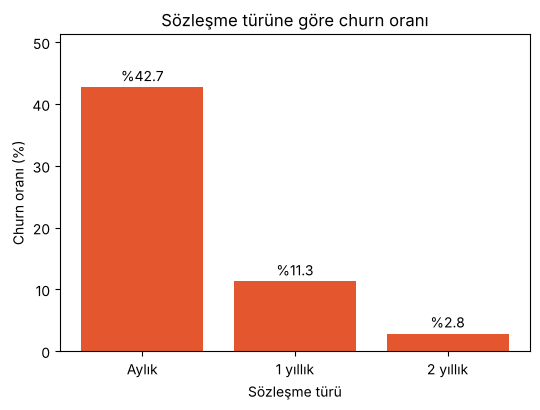

In [5]:
# Grafik 2: sözleşme türüne göre churn oranı
sira = ["Month-to-month", "One year", "Two year"]
etiket = ["Aylık", "1 yıllık", "2 yıllık"]
orn = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reindex(sira)
plt.figure(figsize=(5.5, 4.2))
bars = plt.bar(etiket, orn.values, color="#E4572E")
for b, v in zip(bars, orn.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 1, f"%{v:.1f}", ha="center")
plt.title("Sözleşme türüne göre churn oranı")
plt.xlabel("Sözleşme türü")
plt.ylabel("Churn oranı (%)")
plt.ylim(0, orn.max() * 1.2)
plt.tight_layout()
plt.savefig("grafik2_sozlesme.png", dpi=150)
plt.show()
R["sozlesme_churn"] = {k: round(float(v), 1) for k, v in zip(etiket, orn.values)}

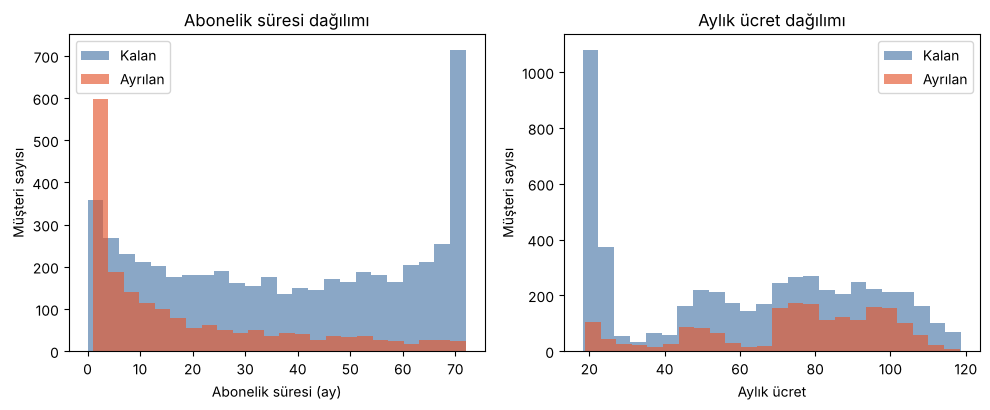

       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


In [6]:
# Grafik 3: abonelik süresi ve aylık ücret dağılımı
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for d, renk, ad in [("No", "#4C78A8", "Kalan"), ("Yes", "#E4572E", "Ayrılan")]:
    s = df[df["Churn"] == d]
    ax[0].hist(s["tenure"], bins=24, alpha=0.65, color=renk, label=ad)
    ax[1].hist(s["MonthlyCharges"], bins=24, alpha=0.65, color=renk, label=ad)
ax[0].set_title("Abonelik süresi dağılımı")
ax[0].set_xlabel("Abonelik süresi (ay)")
ax[0].set_ylabel("Müşteri sayısı")
ax[0].legend()
ax[1].set_title("Aylık ücret dağılımı")
ax[1].set_xlabel("Aylık ücret")
ax[1].set_ylabel("Müşteri sayısı")
ax[1].legend()
plt.tight_layout()
plt.savefig("grafik3_sure_ucret.png", dpi=150)
plt.show()

ort = df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1)
print(ort)
R["ort_tenure"] = {k: float(v) for k, v in ort["tenure"].items()}
R["ort_ucret"] = {k: float(v) for k, v in ort["MonthlyCharges"].items()}

In [7]:
# Ek inceleme: internet hizmeti ve ödeme yöntemine göre churn oranı
for kol in ["InternetService", "PaymentMethod"]:
    t = df.groupby(kol)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).round(1)
    print(kol, t.to_dict())
    R["churn_" + kol] = t.to_dict()

InternetService {'DSL': 19.0, 'Fiber optic': 41.9, 'No': 7.4}
PaymentMethod {'Bank transfer (automatic)': 16.7, 'Credit card (automatic)': 15.2, 'Electronic check': 45.3, 'Mailed check': 19.1}


**Gözlemler**

1. Aylık sözleşmeli müşterilerde churn oranı çok yüksek, 2 yıllık sözleşmelilerde ise çok düşük. Sözleşme türü en güçlü ipuçlarından biri.
2. Ayrılan müşteriler genelde yeni müşteriler: abonelik süresi ayrılanlarda belirgin biçimde daha kısa.
3. Ayrılan müşterilerin aylık ücreti ortalamada daha yüksek. Pahalı paketlerde fiyat hassasiyeti artıyor olabilir.
4. Fiber internet kullananlarda ve elektronik çekle ödeyenlerde churn oranı diğer gruplardan yüksek.

## 4. Veri Ön İşleme

In [8]:
data = df.copy()

# 4.1 TotalCharges metin olarak gelmiş, 11 satırda boş. Boş olanların hepsi abonelik süresi 0 olan yeni müşteriler.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
bos = data["TotalCharges"].isnull()
print("TotalCharges boş satır:", bos.sum(), "| bunların tenure değerleri:", data.loc[bos, "tenure"].unique())
data["TotalCharges"] = data["TotalCharges"].fillna(0)  # henüz fatura kesilmemiş, yani 0
R["bos_totalcharges"] = int(bos.sum())

# 4.2 Kimlik sütununu at, hedefi 0/1 yap
data = data.drop(columns="customerID")
y = (data["Churn"] == "Yes").astype(int)
X = data.drop(columns="Churn")

# 4.3 Sütun türleri
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bin_cols = ["SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols + bin_cols]
print("Kategorik sütun sayısı:", len(cat_cols))

# 4.4 Eğitim ve test bölmesi (sınıf oranı korunarak)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Eğitim:", X_train.shape, "| Test:", X_test.shape)
print("Eğitimde churn oranı:", round(y_train.mean(), 3), "| Testte:", round(y_test.mean(), 3))
R["train_n"] = int(len(X_train))
R["test_n"] = int(len(X_test))

# 4.5 Dönüşümler: sayısallar ölçeklenir, kategorikler one hot encoding ile sayısallaştırılır.
# Dönüştürücü bir pipeline içinde olduğu için yalnızca eğitim verisine fit edilir (veri sızıntısı olmaz).
def yeni_onisleme():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ])

TotalCharges boş satır: 11 | bunların tenure değerleri: [0]
Kategorik sütun sayısı: 15
Eğitim: (5634, 19) | Test: (1409, 19)
Eğitimde churn oranı: 0.265 | Testte: 0.265


**Ön işleme açıklaması:** Eksik veri yalnızca `TotalCharges` içinde ve metin biçimindeydi, bu yüzden sayıya çevirdik. Boş değerler henüz fatura kesilmemiş yeni müşterilere ait olduğu için 0 ile doldurduk. Aykırı değer olarak silinecek bir kayıt bulunmadı, aylık ücret ve süre makul aralıklarda. Kategorik sütunlar one hot encoding ile, sayısal sütunlar standartlaştırma ile hazırlandı. Bölme sırasında churn oranı eğitim ve testte aynı tutuldu (stratify).

## 5. Model Seçimi / Tasarımı

1. **Logistic Regression (temel model):** Hızlı, katsayıları yorumlanabilir, doğrusal ilişkileri yakalar. `class_weight="balanced"` ile az görülen churn sınıfına daha fazla ağırlık verilir.
2. **Random Forest (ikinci model):** Doğrusal olmayan ilişkileri ve değişkenler arası etkileşimleri yakalayabilir. `class_weight="balanced_subsample"` kullanılır.

Aynı train/test verisi ve aynı çapraz doğrulama ile karşılaştırılır.

## 6. Model Eğitimi
Eğitim verisi üzerinde 5 katlı stratified çapraz doğrulama ve GridSearchCV ile hiperparametre aranır. Ölçüt: churn sınıfının F1 skoru. Test verisi arama sırasında kullanılmaz.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_pipe = Pipeline([("pre", yeni_onisleme()),
                    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
lr_grid = GridSearchCV(lr_pipe, {"clf__C": [0.01, 0.1, 1, 10]}, scoring="f1", cv=cv, n_jobs=-1)
lr_grid.fit(X_train, y_train)
print("LR en iyi parametre:", lr_grid.best_params_, "| CV F1:", round(lr_grid.best_score_, 3))

rf_pipe = Pipeline([("pre", yeni_onisleme()),
                    ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])
rf_grid = GridSearchCV(rf_pipe, {"clf__max_depth": [5, 8, 12, None],
                                 "clf__min_samples_leaf": [1, 5, 10]},
                       scoring="f1", cv=cv, n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("RF en iyi parametre:", rf_grid.best_params_, "| CV F1:", round(rf_grid.best_score_, 3))

modeller = {"Logistic Regression": lr_grid.best_estimator_, "Random Forest": rf_grid.best_estimator_}
R["lr_param"] = {k: (None if v is None else float(v)) for k, v in lr_grid.best_params_.items()}
R["rf_param"] = {k: (None if v is None else int(v)) for k, v in rf_grid.best_params_.items()}
R["lr_cv_f1"] = round(float(lr_grid.best_score_), 3)
R["rf_cv_f1"] = round(float(rf_grid.best_score_), 3)

LR en iyi parametre: {'clf__C': 1} | CV F1: 0.629


RF en iyi parametre: {'clf__max_depth': 8, 'clf__min_samples_leaf': 10} | CV F1: 0.636


## 7. Model Değerlendirme

In [10]:
tablo = []
tahminler = {}
for ad, m in modeller.items():
    p = m.predict_proba(X_test)[:, 1]
    yt = (p >= 0.5).astype(int)
    tahminler[ad] = (p, yt)
    tablo.append({
        "Model": ad,
        "Accuracy": accuracy_score(y_test, yt),
        "Precision": precision_score(y_test, yt),
        "Recall": recall_score(y_test, yt),
        "F1": f1_score(y_test, yt),
        "ROC AUC": roc_auc_score(y_test, p),
        "Eğitim F1": f1_score(y_train, m.predict(X_train)),
    })
sonuc = pd.DataFrame(tablo).set_index("Model").round(3)
print("Çoğunluk sınıfı tahmini accuracy:", round(1 - y_test.mean(), 3))
sonuc

Çoğunluk sınıfı tahmini accuracy: 0.735


,Accuracy,Precision,Recall,F1,ROC AUC,Eğitim F1
Model,,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.841,0.634
Random Forest,0.756,0.527,0.786,0.631,0.844,0.674


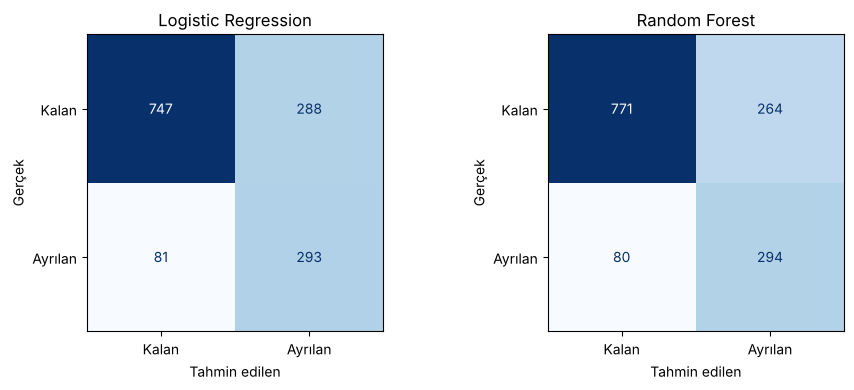

{'Logistic Regression': [[747, 288], [81, 293]], 'Random Forest': [[771, 264], [80, 294]]}


In [11]:
R["metrikler"] = sonuc.to_dict(orient="index")
R["cogunluk_acc"] = round(float(1 - y_test.mean()), 3)

# Confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
for a, (ad, (p, yt)) in zip(ax, tahminler.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, yt, display_labels=["Kalan", "Ayrılan"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(ad)
    a.set_xlabel("Tahmin edilen")
    a.set_ylabel("Gerçek")
plt.tight_layout()
plt.savefig("grafik4_confusion.png", dpi=150)
plt.show()
R["confusion"] = {ad: confusion_matrix(y_test, yt).tolist() for ad, (p, yt) in tahminler.items()}
print(R["confusion"])

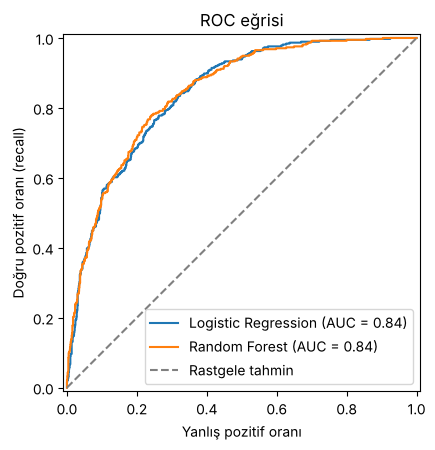

In [12]:
# ROC eğrisi
fig, a = plt.subplots(figsize=(5.5, 4.6))
for ad, m in modeller.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=a, name=ad)
a.plot([0, 1], [0, 1], "--", color="gray", label="Rastgele tahmin")
a.set_title("ROC eğrisi")
a.set_xlabel("Yanlış pozitif oranı")
a.set_ylabel("Doğru pozitif oranı (recall)")
a.legend(loc="lower right")
plt.tight_layout()
plt.savefig("grafik5_roc.png", dpi=150)
plt.show()

## 8. Sonuçların Yorumlanması ve Hata Analizi

In [13]:
# En iyi modeli test verisine bakmadan, çapraz doğrulama F1 skoruna göre seçiyoruz.
en_iyi_ad = "Logistic Regression" if lr_grid.best_score_ >= rf_grid.best_score_ else "Random Forest"
en_iyi = modeller[en_iyi_ad]
print("Seçilen model:", en_iyi_ad)
R["en_iyi"] = en_iyi_ad

p, yt = tahminler[en_iyi_ad]
hata = X_test.copy()
hata["gercek"] = y_test.values
hata["tahmin"] = yt
def grup(r):
    if r.gercek == 1 and r.tahmin == 1: return "Doğru yakalanan churn (TP)"
    if r.gercek == 1 and r.tahmin == 0: return "Kaçırılan churn (FN)"
    if r.gercek == 0 and r.tahmin == 1: return "Yanlış alarm (FP)"
    return "Doğru kalan (TN)"
hata["grup"] = hata.apply(grup, axis=1)
profil = hata.groupby("grup").agg(
    adet=("tenure", "size"),
    ort_sure=("tenure", "mean"),
    ort_ucret=("MonthlyCharges", "mean"),
    aylik_sozlesme=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    fiber=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
).round(1)
profil

Seçilen model: Random Forest


,adet,ort_sure,ort_ucret,aylik_sozlesme,fiber
grup,,,,,
Doğru kalan (TN),771,43.9,56.7,23.9,23.1
Doğru yakalanan churn (TP),294,11.7,74.0,99.3,74.8
Kaçırılan churn (FN),80,33.9,68.2,46.2,40.0
Yanlış alarm (FP),264,18.7,73.3,98.5,69.3


In [14]:
R["hata_profil"] = profil.to_dict(orient="index")

In [15]:
# Eşik ayarı: eşik, test verisine değil eğitim verisinin çapraz doğrulama tahminlerine bakılarak seçilir.
# Amaç ayrılacak müşterileri kaçırmamak olduğu için recall'a daha çok ağırlık veren F2 skoru kullanılır.
cv_p = cross_val_predict(en_iyi, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
pr, rc, th = precision_recall_curve(y_train, cv_p)
f2 = 5 * pr[:-1] * rc[:-1] / (4 * pr[:-1] + rc[:-1] + 1e-12)
esik = float(th[np.argmax(f2)])
print("Seçilen eşik:", round(esik, 3))

satirlar = []
for e in [0.5, esik]:
    yy = (p >= e).astype(int)
    satirlar.append({"Eşik": round(e, 3), "Accuracy": accuracy_score(y_test, yy),
                     "Precision": precision_score(y_test, yy), "Recall": recall_score(y_test, yy),
                     "F1": f1_score(y_test, yy)})
esik_tablo = pd.DataFrame(satirlar).set_index("Eşik").round(3)
R["esik"] = round(esik, 3)
R["esik_tablo"] = {str(k): v for k, v in esik_tablo.to_dict(orient="index").items()}
esik_tablo

Seçilen eşik: 0.335


,Accuracy,Precision,Recall,F1
Eşik,,,,
0.500,0.756,0.527,0.786,0.631
0.335,0.680,0.448,0.888,0.596


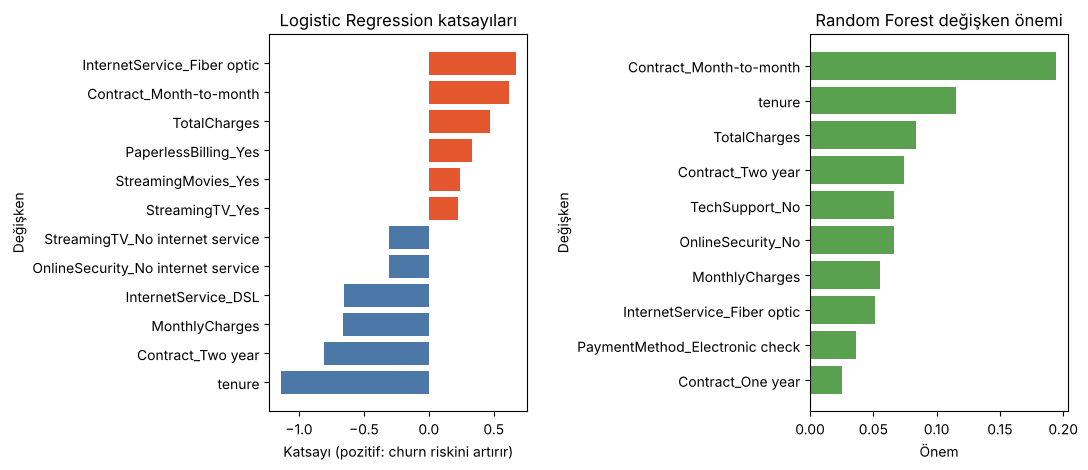

{'InternetService_Fiber optic': 0.67, 'Contract_Month-to-month': 0.62, 'TotalCharges': 0.47, 'PaperlessBilling_Yes': 0.34, 'StreamingMovies_Yes': 0.24}
{'tenure': -1.14, 'Contract_Two year': -0.81, 'MonthlyCharges': -0.66, 'InternetService_DSL': -0.66, 'OnlineSecurity_No internet service': -0.31}
{'Contract_Month-to-month': 0.194, 'tenure': 0.115, 'TotalCharges': 0.084, 'Contract_Two year': 0.074, 'TechSupport_No': 0.067}


In [16]:
# Değişken etkileri
def temiz(n):
    return n.split("__", 1)[1] if "__" in n else n

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))

lr_m = modeller["Logistic Regression"]
isimler = [temiz(n) for n in lr_m.named_steps["pre"].get_feature_names_out()]
kats = pd.Series(lr_m.named_steps["clf"].coef_[0], index=isimler)
sec = pd.concat([kats.sort_values().head(6), kats.sort_values().tail(6)])
ax[0].barh(sec.index, sec.values, color=["#4C78A8" if v < 0 else "#E4572E" for v in sec.values])
ax[0].set_title("Logistic Regression katsayıları")
ax[0].set_xlabel("Katsayı (pozitif: churn riskini artırır)")
ax[0].set_ylabel("Değişken")

rf_m = modeller["Random Forest"]
isimler = [temiz(n) for n in rf_m.named_steps["pre"].get_feature_names_out()]
imp = pd.Series(rf_m.named_steps["clf"].feature_importances_, index=isimler).sort_values().tail(10)
ax[1].barh(imp.index, imp.values, color="#59A14F")
ax[1].set_title("Random Forest değişken önemi")
ax[1].set_xlabel("Önem")
ax[1].set_ylabel("Değişken")
plt.tight_layout()
plt.savefig("grafik6_onem.png", dpi=150)
plt.show()
R["lr_en_artiran"] = {k: round(float(v), 2) for k, v in kats.sort_values().tail(5)[::-1].items()}
R["lr_en_azaltan"] = {k: round(float(v), 2) for k, v in kats.sort_values().head(5).items()}
R["rf_onem"] = {k: round(float(v), 3) for k, v in imp[::-1].head(5).items()}
print(R["lr_en_artiran"]); print(R["lr_en_azaltan"]); print(R["rf_onem"])

**Yorum ve geliştirme önerileri** için rapora bakınız. Sayısal sonuçlar yukarıdaki hücrelerdedir.